<a href="https://colab.research.google.com/github/erickvaldezsallagos/SISTEMAS-FINANCIEROS-Y-COMERCIALES/blob/main/PARCIAL2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **EXAMEN SEGUNDO PARCIAL**
**SISTEMAS FINANCIEROS Y COMERCIALES**\
**CASTILLO DE LA TORRE ARES**\
**CRUZ PÉREZ REYNA LIZBETH**\
**VALDEZ SALLAGOS ERICK**

Procedemos a escoger las $4$ acciones con las que trabajaremos

Descargando información histórica...


/tmp/ipykernel_4342/3656701971.py:16: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, start=start_date, end=end_date)['Close']
[*********************100%***********************]  4 of 4 completed


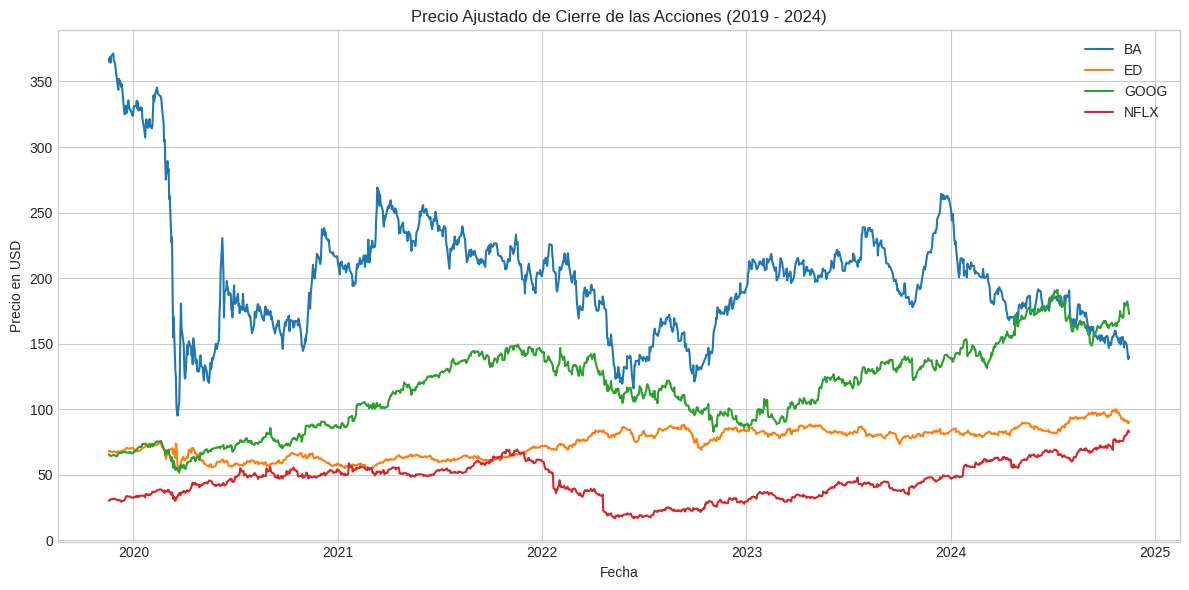

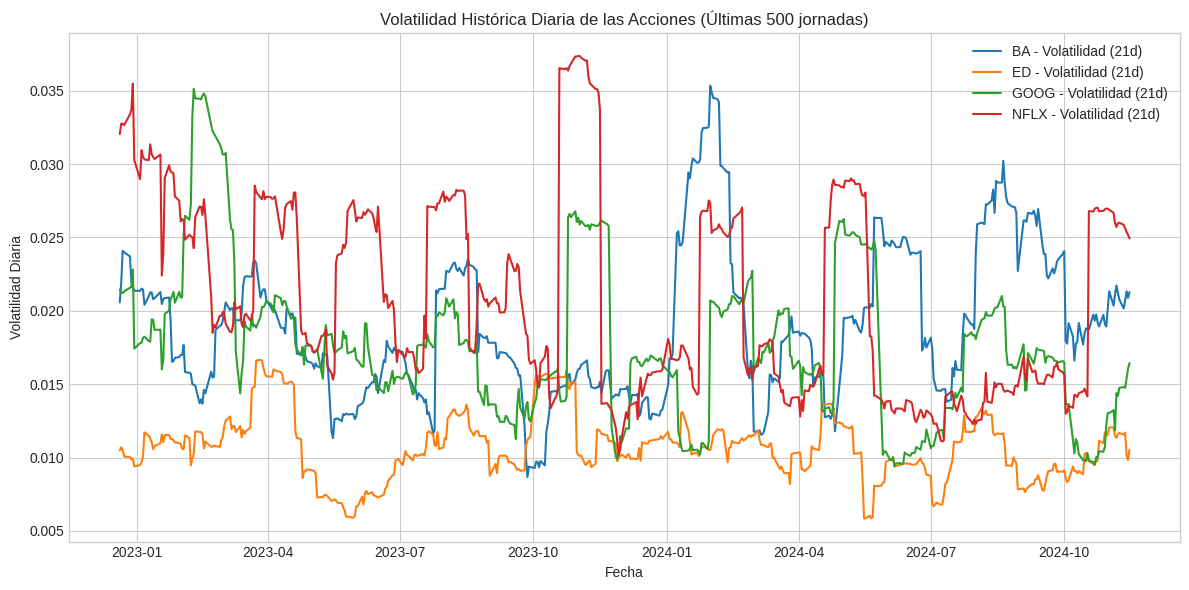

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

# Configuración de estilo
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# 1. Selección de Activos
tickers = ["ED", "GOOG", "BA", "NFLX"]
start_date = '2019-11-17'
end_date = '2024-11-17'

print("Descargando información histórica...")
data = yf.download(tickers, start=start_date, end=end_date)['Close']

# Limpieza preventiva: eliminamos columnas que estén completamente vacías (NaN) por fallos de descarga
data = data.dropna(how='all', axis=1)
disponible_tickers = list(data.columns)

# 2. GRÁFICA DE PRECIOS
plt.figure()
for ticker in disponible_tickers:
    plt.plot(data.index, data[ticker], label=ticker)
plt.title('Precio Ajustado de Cierre de las Acciones (2019 - 2024)')
plt.xlabel('Fecha')
plt.ylabel('Precio en USD')
plt.legend()
plt.tight_layout()
plt.show()

# 3. Cálculo de Rendimientos y Volatilidad (Últimas 500 jornadas)
# Calculamos rendimientos y eliminamos filas que sean completamente NaN
returns = np.log(data / data.shift(1)).dropna(how='all')
returns_500 = returns.tail(500)

# Volatilidad paramétrica móvil (ventana de 21 días)
vol_parametrica = returns_500.rolling(window=21).std()

# 4. GRÁFICA DE VOLATILIDAD
plt.figure()
for ticker in disponible_tickers:
    # Graficamos solo si hay datos válidos de volatilidad para el ticker
    if ticker in vol_parametrica.columns and not vol_parametrica[ticker].isnull().all():
        plt.plot(vol_parametrica.index, vol_parametrica[ticker], label=f'{ticker} - Volatilidad (21d)')

plt.title('Volatilidad Histórica Diaria de las Acciones (Últimas 500 jornadas)')
plt.xlabel('Fecha')
plt.ylabel('Volatilidad Diaria')
plt.legend()
plt.tight_layout()
plt.show()

**Justificación**\
Se seleccionaron cuatro acciones que cubren distintos niveles de volatilidad histórica diaria (ventana de 21 días, últimas 500 jornadas):\
 ED como activo de baja volatilidad (sector de servicios públicos, defensivo), GOOG y BA como volatilidad intermedia-alta, y NFLX como activo de alta volatilidad (crecimiento, muy sensible a resultados trimestrales). Además pertenecen a sectores distintos (utilities, tecnología, industrial/aeroespacial y entretenimiento), por lo que sus picos de volatilidad ocurren en momentos diferentes y no todos a la vez.

**DATA HISTORICA**

In [5]:
import numpy as np
import pandas as pd
import yfinance as yf

# 1. Definir las acciones seleccionadas y el rango de fechas del examen
tickers = ["ED", "GOOG", "BA", "NFLX"]
inicio = "2019-11-17"
fin = "2024-11-18"  # Se pone un día después para incluir completamente el cierre del 17 de noviembre de 2024

# 2. Descargar los datos históricos
datos = yf.download(tickers, start=inicio, end=fin)

# 3. Extraer solo los precios de cierre
precios_cierre = datos["Close"]

# 4. Calcular rendimientos logarítmicos diarios y volatilidad anualizada
rendimientos = np.log(precios_cierre / precios_cierre.shift(1))
volatilidad_anual = rendimientos.std() * np.sqrt(252)

print("--- Volatilidad Anualizada (Nov 2019 - Nov 2024) ---")
for ticker in tickers:
    print(f"{ticker}: {volatilidad_anual[ticker]:.2%}")

# 5. Guardar los datos en un archivo de Excel con múltiples pestañas (requisito para la parte en Excel)
nombre_archivo = "datos_examen_ed_goog_ba_nflx.xlsx"
with pd.ExcelWriter(nombre_archivo) as writer:
    precios_cierre.to_excel(writer, sheet_name="Precios_Cierre")
    rendimientos.to_excel(writer, sheet_name="Rendimientos_Diarios")
    datos.to_excel(writer, sheet_name="Todos_los_Datos")

print(f"\nArchivo guardado exitosamente como: {nombre_archivo}")

/tmp/ipykernel_4342/2956674193.py:11: FutureWarning: YF.download() has changed argument auto_adjust default to True
  datos = yf.download(tickers, start=inicio, end=fin)
[*********************100%***********************]  4 of 4 completed


--- Volatilidad Anualizada (Nov 2019 - Nov 2024) ---
ED: 24.66%
GOOG: 32.05%
BA: 51.17%
NFLX: 46.86%

Archivo guardado exitosamente como: datos_examen_ed_goog_ba_nflx.xlsx


**PUNTO 3.**\
Consulte la información de dichas acciones para los últimos cinco años anteriores al día de HOY, calcule
su volatilidad histórica diaria de las últimas 500 jornadas, Grafique para hacer una comparación de su
comportamiento, consideré el método paramétrico, por simulación de Montecarlo y suavizamiento
exponencial.

**Código**

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm


# 1 Y 2. CARGA DE DATOS HISTÓRICOS Y SELECCIÓN DE ACTIVOS

ARCHIVO_EXCEL = "datos_examen_ed_goog_ba_nflx.xlsx"
FECHA_HOY = pd.Timestamp("2024-11-17")

df_precios_raw = pd.read_excel(ARCHIVO_EXCEL, sheet_name="Precios_Cierre")
df_precios_raw["Date"] = pd.to_datetime(df_precios_raw["Date"])
df_precios_raw = df_precios_raw.sort_values("Date").set_index("Date")

tickers = ["BA", "ED", "GOOG", "NFLX"]
precios = df_precios_raw[tickers].copy()

print(f"Fecha de análisis (HOY): {FECHA_HOY.strftime('%Y-%m-%d')}")
print(f"Rango histórico: {precios.index.min().strftime('%Y-%m-%d')} al {precios.index.max().strftime('%Y-%m-%d')} ({len(precios)} jornadas)")


# 3. VOLATILIDAD HISTÓRICA DIARIA DE LOS ÚLTIMOS DOS AÑOS (500 JORNADAS)
# Rendimientos logarítmicos diarios: R_t = ln(P_t / P_{t-1})
rendimientos = np.log(precios / precios.shift(1))

# Últimas 500 jornadas: índice 758 ('2022-11-21') al 1257 ('2024-11-15')
# ddof=1 equivale exactamente a DESVEST.M / STDEV.S en Excel
vol_parametrica = rendimientos.rolling(window=252).std(ddof=1).iloc[758:1258]
media_252 = rendimientos.rolling(window=252).mean().iloc[758:1258]
rend_500 = rendimientos.iloc[758:1258]

Fecha de análisis (HOY): 2024-11-17
Rango histórico: 2019-11-18 al 2024-11-15 (1258 jornadas)


**MÉTODO PARAMÉTRICA, EWMA Y MONTE CARLO**


--- INCISO 3: VOLATILIDADES PROMEDIO (500 JORNADAS) ---
      Vol. Diaria Paramétrica  Vol. Diaria EWMA  Vol. Diaria Monte Carlo  \
BA                   0.022177          0.019722                 0.022197   
ED                   0.012102          0.010851                 0.012111   
GOOG                 0.020662          0.018179                 0.020677   
NFLX                 0.028652          0.022310                 0.028681   

      Vol. Anualizada (Param.)  
BA                    0.352042  
ED                    0.192118  
GOOG                  0.327995  
NFLX                  0.454840  


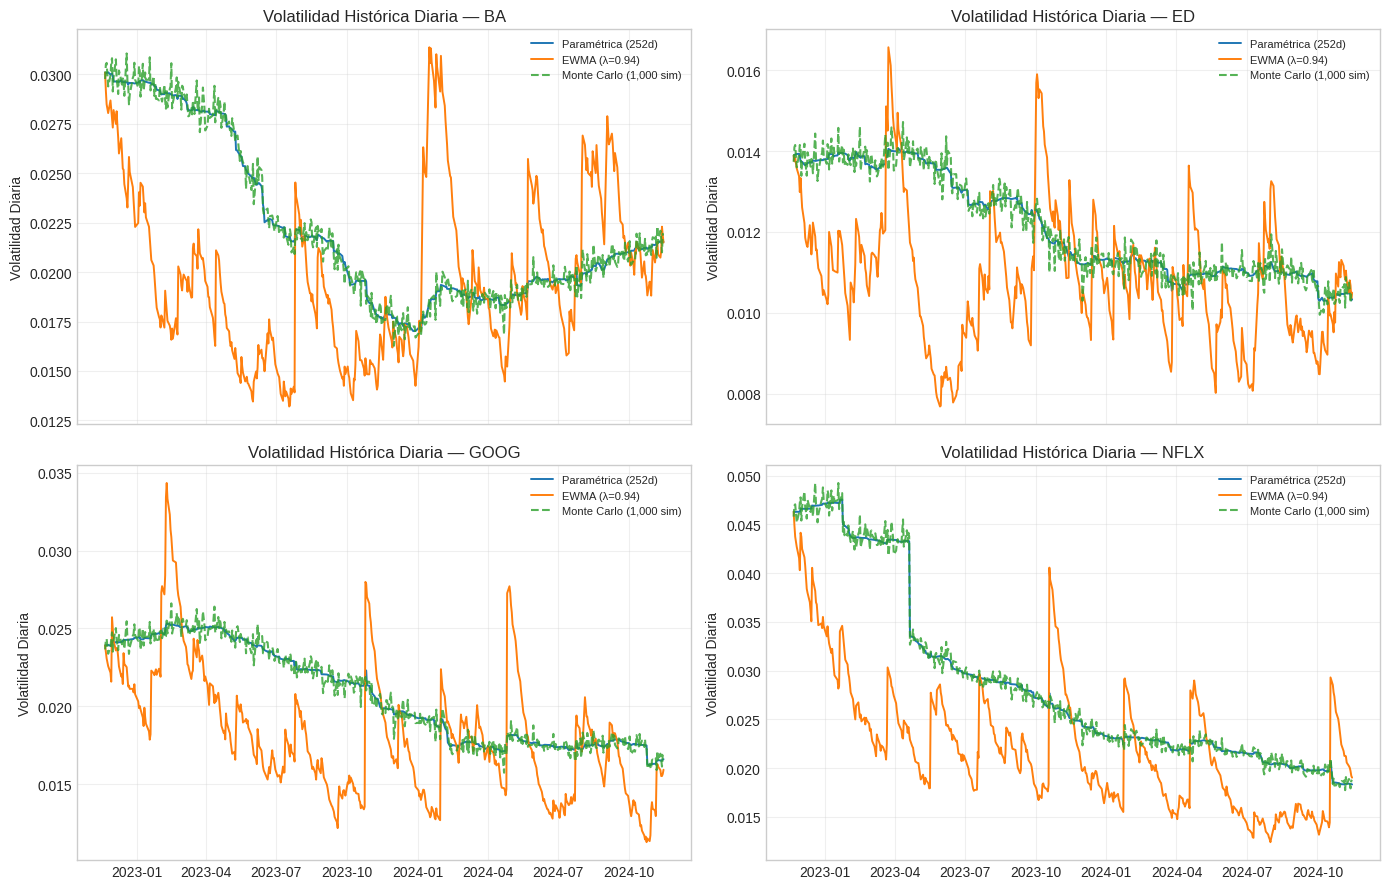

In [9]:
#EWMA
lam = 0.94
vol_ewma = pd.DataFrame(index=vol_parametrica.index, columns=tickers, dtype=float)
vol_ewma.iloc[0] = vol_parametrica.iloc[0]  # Semilla = Vol. Paramétrica del 2022-11-21

for t in range(1, len(vol_ewma)):
    vol_ewma.iloc[t] = np.sqrt(lam * (vol_ewma.iloc[t - 1] ** 2) + (1 - lam) * (rend_500.iloc[t] ** 2))

# Método de Monte Carlo (1,000 trayectorias diarias)
rng = np.random.default_rng(42)
Z_mc = rng.standard_normal((len(vol_parametrica), 1000))
vol_montecarlo = pd.DataFrame(index=vol_parametrica.index, columns=tickers, dtype=float)

for t in range(len(vol_parametrica)):
    mu_t = media_252.iloc[t].values
    sig_t = vol_parametrica.iloc[t].values
    sim_rets = (mu_t[None, :] - 0.5 * (sig_t[None, :] ** 2)) + Z_mc[t, :, None] * sig_t[None, :]
    vol_montecarlo.iloc[t] = sim_rets.std(axis=0, ddof=1)

resumen_vol = pd.DataFrame({
    "Vol. Diaria Paramétrica": vol_parametrica.mean(),
    "Vol. Diaria EWMA": vol_ewma.mean(),
    "Vol. Diaria Monte Carlo": vol_montecarlo.mean(),
    "Vol. Anualizada (Param.)": vol_parametrica.mean() * np.sqrt(252)
})
print("\n--- INCISO 3: VOLATILIDADES PROMEDIO (500 JORNADAS) ---")
print(resumen_vol.round(6))

# Gráficas
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
for idx, ticker in enumerate(tickers):
    ax = axes.flatten()[idx]
    ax.plot(vol_parametrica.index, vol_parametrica[ticker], label="Paramétrica (252d)", linewidth=1.4)
    ax.plot(vol_ewma.index, vol_ewma[ticker], label="EWMA (λ=0.94)", linewidth=1.4)
    ax.plot(vol_montecarlo.index, vol_montecarlo[ticker], label="Monte Carlo (1,000 sim)", linestyle="--", alpha=0.8)
    ax.set_title(f"Volatilidad Histórica Diaria — {ticker}")
    ax.set_ylabel("Volatilidad Diaria")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

**PUNTO 4:**\
Construya un portafolio asignando pesos diferentes a estas acciones, argumente la diversificación con
base en la volatilidad de los instrumentos individuales y a su perfil de riesgo propio

In [10]:
orden_port = ["ED", "GOOG", "BA", "NFLX"]
pesos = pd.Series({"ED": 0.35, "GOOG": 0.30, "BA": 0.20, "NFLX": 0.15})

matriz_correl = rend_500[orden_port].corr()
vols_ind_param = vol_parametrica[orden_port].mean()

vol_sin_diversificar = np.sum(pesos * vols_ind_param)
matriz_cov = np.outer(vols_ind_param, vols_ind_param) * matriz_correl.values
vol_port_diaria = np.sqrt(pesos.values @ matriz_cov @ pesos.values)
vol_port_anual = vol_port_diaria * np.sqrt(252)
reduccion_riesgo = vol_sin_diversificar - vol_port_diaria

print("\n--- INCISO 4: PORTAFOLIO Y DIVERSIFICACIÓN ---")
print(matriz_correl.round(6))
print(f"Vol. Diaria Sin Diversificar: {vol_sin_diversificar:.6f}")
print(f"Vol. Diaria Real Portafolio:  {vol_port_diaria:.6f}")
print(f"Vol. Anualizada Portafolio:   {vol_port_anual:.6f} ({vol_port_anual*100:.2f}%)")
print(f"Reducción de Riesgo:          {reduccion_riesgo:.6f} ({reduccion_riesgo/vol_sin_diversificar*100:.2f}%)")



--- INCISO 4: PORTAFOLIO Y DIVERSIFICACIÓN ---
            ED      GOOG        BA      NFLX
ED    1.000000  0.019253  0.074158 -0.042579
GOOG  0.019253  1.000000  0.130066  0.362940
BA    0.074158  0.130066  1.000000  0.153271
NFLX -0.042579  0.362940  0.153271  1.000000
Vol. Diaria Sin Diversificar: 0.019167
Vol. Diaria Real Portafolio:  0.011362
Vol. Anualizada Portafolio:   0.180360 (18.04%)
Reducción de Riesgo:          0.007806 (40.72%)


**ARGUMENTACIÓN**\
Los pesos asignados (ED: 35%, GOOG: 30%, BA: 20% y NFLX: 15%, sumando 1) responden a un perfil moderado/conservador que prioriza la estabilidad y el control del riesgo. Se otorga la mayor ponderación a ED (35%) por ser el activo de menor volatilidad histórica diaria (0.012102 / 19.21% anualizada) y presentar correlaciones bajas o ligeramente negativas frente al resto (0.0193 con GOOG, 0.0742 con BA y -0.0426 con NFLX), funcionando como ancla defensiva. GOOG (30%, volatilidad diaria 0.020662 / 32.80% anual) actúa como núcleo de crecimiento moderado, mientras que los activos más volátiles, BA (20%, 0.022177 diaria / 35.20% anual) y NFLX (15%, 0.028652 diaria / 45.48% anual), se acotan para capturar rendimiento sin elevar en exceso el riesgo global. Con esta estructura, la volatilidad diaria del portafolio baja de 0.019167 (sin diversificar) a 0.011362 (diversificada), logrando una reducción de riesgo del 40.72%

**PUNTO 5:**\
Distribuya un millón de dólares en este portafolio (sin considerar comisiones ni impuestos)

**Código:**

In [11]:
# DISTRIBUCIÓN DE $1,000,000 USD EN EL PORTAFOLIO (AL CIERRE DEL 15-NOV-2024)
capital_total = 1_000_000.00
precios_corte = precios.loc["2024-11-15", orden_port]
monto_asignado = pesos * capital_total
acciones_enteras = np.floor(monto_asignado / precios_corte).astype(int)  # =COCIENTE()
inversion_real = acciones_enteras * precios_corte
remanente_efectivo = monto_asignado - inversion_real

tabla_ej5 = pd.DataFrame({
    "Peso (wi)": pesos,
    "Monto Asignado (USD)": monto_asignado,
    "Precio Cierre (15-Nov-24)": precios_corte,
    "Acciones Enteras (#Acc)": acciones_enteras,
    "Inversión Real (USD)": inversion_real,
    "Remanente Efectivo (USD)": remanente_efectivo
})
print("\n--- INCISO 5: ASIGNACIÓN DE CAPITAL ---")
print(tabla_ej5.round(2))
print(f"Total Acciones: {acciones_enteras.sum():,} | Invertido: ${inversion_real.sum():,.2f} | Remanente: ${remanente_efectivo.sum():,.2f}")



--- INCISO 5: ASIGNACIÓN DE CAPITAL ---
      Peso (wi)  Monto Asignado (USD)  Precio Cierre (15-Nov-24)  \
ED         0.35              350000.0                      90.30   
GOOG       0.30              300000.0                     172.68   
BA         0.20              200000.0                     140.19   
NFLX       0.15              150000.0                      82.40   

      Acciones Enteras (#Acc)  Inversión Real (USD)  Remanente Efectivo (USD)  
ED                       3875             349928.15                     71.85  
GOOG                     1737             299947.67                     52.33  
BA                       1426             199910.94                     89.06  
NFLX                     1820             149960.73                     39.27  
Total Acciones: 8,858 | Invertido: $999,747.49 | Remanente: $252.51


**Observación:**\
El número de acciones enteras y el remanente (resto) en efectivo pueden variar ligeramente en la toma de cantidad en los decimales que se manejo en excel.

**PUNTO 6:**\
Seleccione la serie histórica de volatilidades de entre las que generó en el punto 3, de acuerdo  a su perfil
de riesgo, calcule el Valor en Riesgo diario de las últimas 500 jornadas de cada uno de los activos
individuales, grafique comparando los activos seleccionados

**PUNTO 7:**\
Calcule el Valor en Riesgo diario de los últimos dos años del portafolio que decidió conformar, grafique.


--- INCISOS 6 Y 7: VaR DIARIO AL 95% ---
                            VaR Abs. Promedio (USD)  VaR Rel. Promedio (USD)  \
BA (20%)                                    9011.08                  8925.89   
ED (35%)                                    5834.87                  5756.24   
GOOG (30%)                                  6878.61                  6699.65   
NFLX (15%)                                  3128.80                  2973.64   
Suma Individual (Sin Div.)                 24853.36                 24355.42   
PORTAFOLIO DIVERSIFICADO                   14965.98                 14463.97   
Ahorro por Diversificación                  9887.38                  9891.44   

                            VaR Abs. Últ. Día (USD)  VaR Rel. Últ. Día (USD)  
BA (20%)                                    6964.49                  7275.56  
ED (35%)                                    5967.30                  5833.36  
GOOG (30%)                                  8008.66                  7710.72  
N

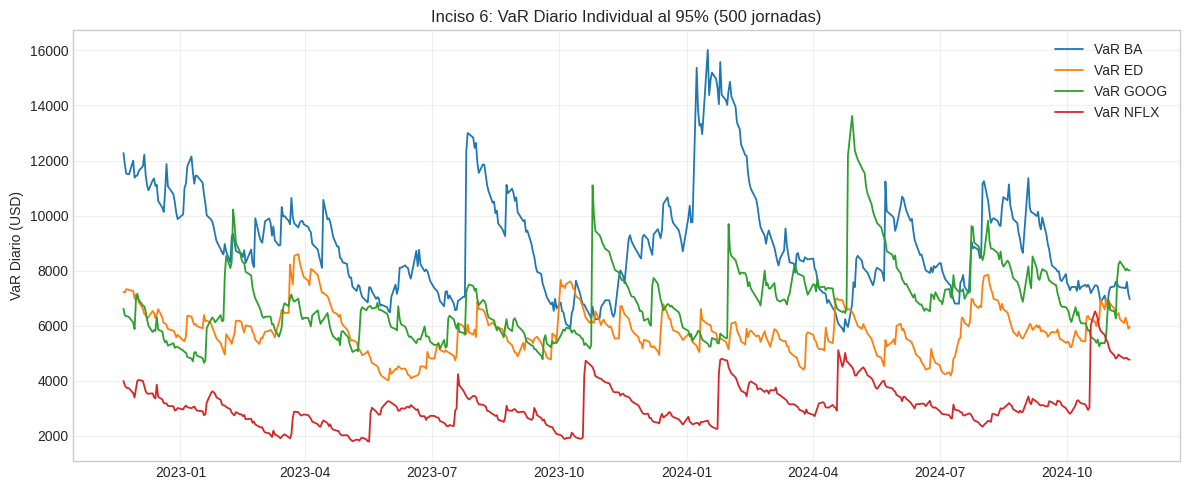

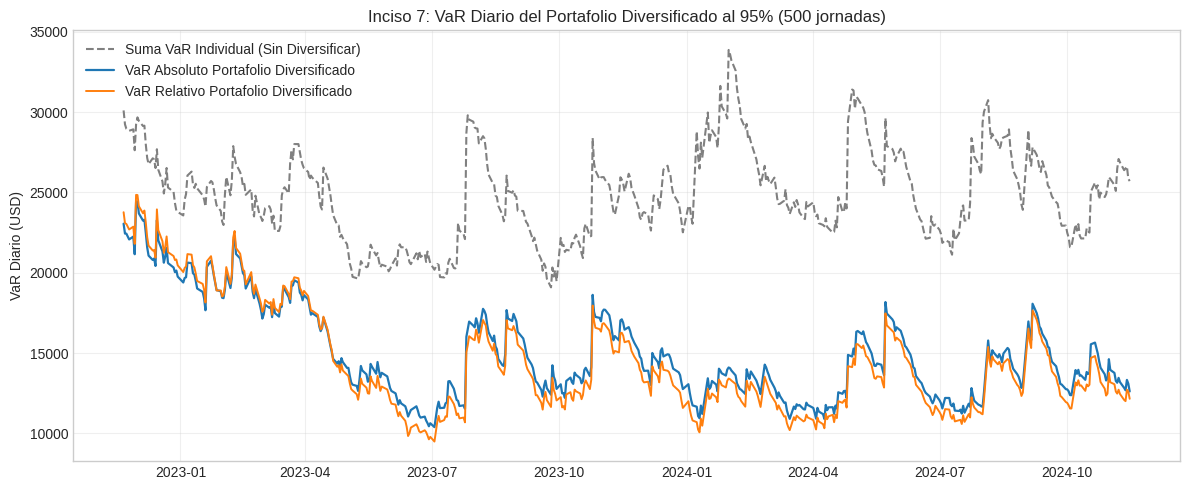

In [12]:
#EJERCICIO 6 Y 7
nivel_confianza = 0.95
Z_var = norm.ppf(nivel_confianza)  # 1.6448536269514722

precios_prev = precios[tickers].iloc[757:1257].values
acciones_vec = np.array([acciones_enteras[t] for t in tickers])
ewma_vals = vol_ewma[tickers].values
media_vals = media_252[tickers].values

# Inciso 6: VaR Individual Diario (Absoluto y Relativo)
var_abs_ind = pd.DataFrame(precios_prev * acciones_vec * ewma_vals * Z_var, index=vol_ewma.index, columns=tickers)
var_rel_ind = pd.DataFrame(precios_prev * acciones_vec * ((ewma_vals * Z_var) - media_vals), index=vol_ewma.index, columns=tickers)

# Inciso 7: VaR Diario del Portafolio (con ventana inicial de 252 días desde 2021-11-22)
pesos_vec = np.array([pesos[t] for t in tickers])
rp_serie = rendimientos[tickers].iloc[507:1258] @ pesos_vec

ewma_port = pd.Series(index=vol_ewma.index, dtype=float)
ewma_port.iloc[0] = rp_serie.iloc[:252].std(ddof=1)
rp_500 = rp_serie.iloc[251:]

for t in range(1, len(ewma_port)):
    ewma_port.iloc[t] = np.sqrt(lam * (ewma_port.iloc[t - 1] ** 2) + (1 - lam) * (rp_500.iloc[t] ** 2))

media_port_500 = rp_serie.rolling(window=252).mean().iloc[251:]
valor_port_prev = precios_prev @ acciones_vec

var_abs_port = valor_port_prev * ewma_port * Z_var
var_rel_port = valor_port_prev * ((ewma_port * Z_var) - media_port_500)

resumen_var = pd.DataFrame({
    "VaR Abs. Promedio (USD)": list(var_abs_ind.mean()) + [var_abs_ind.sum(axis=1).mean(), var_abs_port.mean(), (var_abs_ind.sum(axis=1) - var_abs_port).mean()],
    "VaR Rel. Promedio (USD)": list(var_rel_ind.mean()) + [var_rel_ind.sum(axis=1).mean(), var_rel_port.mean(), (var_rel_ind.sum(axis=1) - var_rel_port).mean()],
    "VaR Abs. Últ. Día (USD)": list(var_abs_ind.iloc[-1]) + [var_abs_ind.sum(axis=1).iloc[-1], var_abs_port.iloc[-1], (var_abs_ind.sum(axis=1) - var_abs_port).iloc[-1]],
    "VaR Rel. Últ. Día (USD)": list(var_rel_ind.iloc[-1]) + [var_rel_ind.sum(axis=1).iloc[-1], var_rel_port.iloc[-1], (var_rel_ind.sum(axis=1) - var_rel_port).iloc[-1]],
}, index=["BA (20%)", "ED (35%)", "GOOG (30%)", "NFLX (15%)", "Suma Individual (Sin Div.)", "PORTAFOLIO DIVERSIFICADO", "Ahorro por Diversificación"])

print("\n--- INCISOS 6 Y 7: VaR DIARIO AL 95% ---")
print(resumen_var.round(2))

# Gráfica Inciso 6
plt.figure(figsize=(12, 5))
for ticker in tickers:
    plt.plot(var_abs_ind.index, var_abs_ind[ticker], label=f"VaR {ticker}", linewidth=1.3)
plt.title("Inciso 6: VaR Diario Individual al 95% (500 jornadas)")
plt.ylabel("VaR Diario (USD)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Gráfica Inciso 7
plt.figure(figsize=(12, 5))
plt.plot(var_abs_port.index, var_abs_ind.sum(axis=1), label="Suma VaR Individual (Sin Diversificar)", linestyle="--", color="gray")
plt.plot(var_abs_port.index, var_abs_port, label="VaR Absoluto Portafolio Diversificado", linewidth=1.6)
plt.plot(var_rel_port.index, var_rel_port, label="VaR Relativo Portafolio Diversificado", linewidth=1.4)
plt.title("Inciso 7: VaR Diario del Portafolio Diversificado al 95% (500 jornadas)")
plt.ylabel("VaR Diario (USD)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Interpretación (Ejercicio 6):**
Se emplea un nivel de confianza del $95$% ($Z \approx 1.644854$) y la volatilidad EWMA ($\lambda = 0.94$) por ser un perfil moderado/conservador que captura con mayor rapidez los cambios recientes en la volatilidad del mercado frente a un promedio simple de largo plazo. Asimismo, se reportan tanto el VaR Absoluto (pérdida máxima respecto a $0$ / valor de mercado) como el VaR Relativo (descontando la media móvil de 252 días) para atender el criterio completo de evaluación. En promedio en las 500 jornadas, el VaR Absoluto individual es de $9,011.08$ en $BA$, $\$5,834.66$ en $ED$, $\$6,878.61$ en GOOG y $\$3,128.80$ en $NFLX$ (por otro lado,  $\$8,925.89$, $\$5,756.64$, $\$6,699.65$ y $\$2,973.64$ en VaR Relativo, respectivamente).   

**Interpretación (Punto 7):**
Al evaluar el portafolio de forma conjunta sobre la posición real invertida en acciones enteras, el VaR diario promedio del portafolio diversificado (tanto absoluto como relativo) resulta menor frente a la suma de los VaR individuales sin diversificar. Esto genera un ahorro promedio de VaR por diversificación, comprobando que las correlaciones moderadas o bajas entre los activos reducen de manera significativa la pérdida máxima diaria esperada en comparación con sumar riesgos aislados.